# Лабораторна робота №6
## Дослідження штучної нейронної мережі

**Мета:** виконати побудову, навчання та оцінювання багатошарової нейронної мережі типу MLP з використанням TensorFlow/Keras; виконати підготовку даних, налаштування архітектури мережі та процесу навчання, використати validation-вибірку, а також дослідити вплив методів регуляризації на узагальнювальну здатність моделі.

Набір даних - **Fashion-MNIST**: 70 000 чорно-білих зображень одягу розміром 28×28 пікселів, 10 класів. Задача - багатокласова класифікація.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import tensorflow as tf

## 1. Завантаження набору даних

In [2]:
from tensorflow.keras.datasets import fashion_mnist

(X_full, y_full), (X_test, y_test) = fashion_mnist.load_data()

class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

print("Навчальна частина:", X_full.shape, y_full.shape)
print("Тестова частина:", X_test.shape, y_test.shape)

Навчальна частина: (60000, 28, 28) (60000,)
Тестова частина: (10000, 28, 28) (10000,)


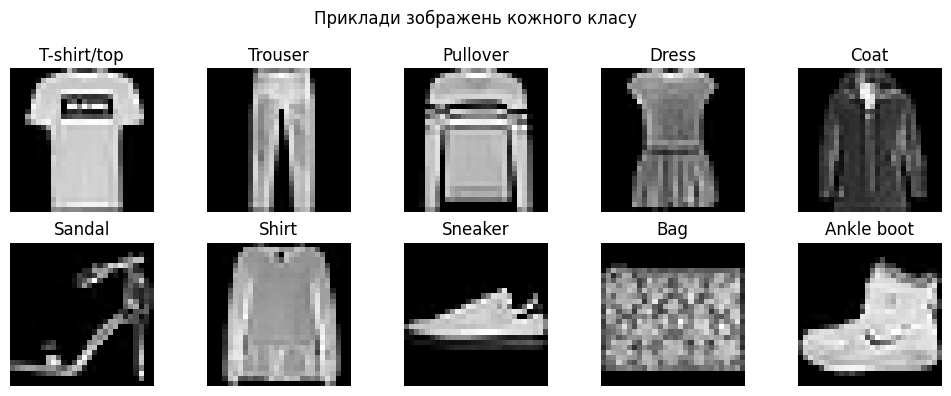

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))

for i, ax in enumerate(axes.ravel()):
    index = np.where(y_full == i)[0][0]
    ax.imshow(X_full[index], cmap="gray")
    ax.set_title(class_names[i])
    ax.axis("off")

plt.suptitle("Приклади зображень кожного класу")
plt.tight_layout()
plt.show()

Кожен об'єкт - це зображення 28×28 пікселів, тобто 784 вхідні ознаки (яскравість кожного пікселя). Цільова змінна `y` - номер класу одягу від 0 до 9.

## 2. Початковий аналіз даних

In [4]:
print("Тип даних:", X_full.dtype)
print("Мінімальне значення пікселя:", X_full.min())
print("Максимальне значення пікселя:", X_full.max())
print("Кількість ознак (пікселів):", X_full.shape[1] * X_full.shape[2])
print("Пропусків у X:", np.isnan(X_full).sum() + np.isnan(X_test).sum())
print("Кількість класів:", len(np.unique(y_full)))

Тип даних: uint8
Мінімальне значення пікселя: 0
Максимальне значення пікселя: 255
Кількість ознак (пікселів): 784
Пропусків у X: 0
Кількість класів: 10


In [5]:
class_table = pd.DataFrame({
    "Клас": class_names,
    "Кількість у train": np.bincount(y_full),
    "Кількість у test": np.bincount(y_test)
})
class_table

,Клас,Кількість у train,Кількість у test
0,T-shirt/top,6000,1000
1,Trouser,6000,1000
2,Pullover,6000,1000
3,Dress,6000,1000
4,Coat,6000,1000
5,Sandal,6000,1000
6,Shirt,6000,1000
7,Sneaker,6000,1000
8,Bag,6000,1000
9,Ankle boot,6000,1000


Дані складаються з 60 000 зображень для навчання і 10 000 для тесту. Кожне зображення має 28×28 = 784 пікселі, тип даних `uint8`, значення від 0 (чорний) до 255 (білий). Пропусків немає. Усі ознаки числові (яскравість пікселів), категоріальних ознак немає, тому кодувати нічого не потрібно. Цільова змінна має 10 класів, і вони повністю збалансовані: по 6000 зображень кожного класу в навчальній частині і по 1000 у тестовій. Матриця ознак X - це масив зображень, вектор y - номери класів.

## 3. Поділ на навчальну, валідаційну та тестову вибірки

In [6]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X_full, y_full, test_size=0.2, random_state=42, stratify=y_full
)

print("Навчальна вибірка:", X_train.shape)
print("Валідаційна вибірка:", X_val.shape)
print("Тестова вибірка:", X_test.shape)

Навчальна вибірка: (48000, 28, 28)
Валідаційна вибірка: (12000, 28, 28)
Тестова вибірка: (10000, 28, 28)


In [7]:
split_table = pd.DataFrame({
    "Train": np.bincount(y_train),
    "Validation": np.bincount(y_val),
    "Test": np.bincount(y_test)
}, index=class_names)
split_table

,Train,Validation,Test
T-shirt/top,4800,1200,1000
Trouser,4800,1200,1000
Pullover,4800,1200,1000
Dress,4800,1200,1000
Coat,4800,1200,1000
Sandal,4800,1200,1000
Shirt,4800,1200,1000
Sneaker,4800,1200,1000
Bag,4800,1200,1000
Ankle boot,4800,1200,1000


Готова тестова вибірка (10 000) відкладена до самого кінця. Навчальну частину (60 000) поділено 80/20 зі `stratify` на навчальну (48 000) і валідаційну (12 000) вибірки. На train мережа оновлює ваги, на validation ми стежимо за якістю під час навчання і порівнюємо конфігурації, а на test один раз оцінюємо обрану модель. Завдяки стратифікації в кожній вибірці всі класи представлені однаково: 4800, 1200 і 1000 зображень.

## 4. Попереднє оброблення даних

In [8]:
X_train = X_train.astype("float32") / 255
X_val = X_val.astype("float32") / 255
X_test = X_test.astype("float32") / 255

print("Train: min =", X_train.min(), " max =", X_train.max())
print("Validation: min =", X_val.min(), " max =", X_val.max())
print("Test: min =", X_test.min(), " max =", X_test.max())

Train: min = 0.0  max = 1.0
Validation: min = 0.0  max = 1.0
Test: min = 0.0  max = 1.0


Пропусків немає, категоріальних ознак немає, тому імпутер і кодування не потрібні. Залишається масштабування: значення пікселів поділено на 255, і тепер вони лежать у діапазоні від 0 до 1. Нейронна мережа навчається градієнтним спуском, і з малими однаковими за масштабом вхідними значеннями навчання стабільніше і швидше. Число 255 - це фіксований максимум яскравості, воно не обчислюється з даних, тому однакове перетворення для train, validation і test не створює витоку даних.

## 5. Базова архітектура MLP

In [9]:
tf.keras.utils.set_random_seed(42)

base_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])

base_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

Базова архітектура, як у прикладі:
- **вхідний шар:** зображення 28×28, яке `Flatten` розгортає у вектор з 784 значень (784 вхідні нейрони);
- **два приховані шари:** 128 і 64 нейрони з активацією ReLU;
- **вихідний шар:** 10 нейронів (по одному на клас) з активацією softmax, яка перетворює виходи на ймовірності 10 класів, що в сумі дають 1.

`summary()` показує кількість параметрів (ваг і зміщень) у кожному шарі: 784·128 + 128 = 100 480, 128·64 + 64 = 8 256, 64·10 + 10 = 650, разом **109 386**.

## 6. Функція втрат, оптимізатор і гіперпараметри

In [10]:
LEARNING_RATE = 0.001
BATCH_SIZE = 128
EPOCHS = 20

base_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Learning rate:", LEARNING_RATE)
print("Batch size:", BATCH_SIZE)
print("Кількість епох:", EPOCHS)
print("Кроків (batch) за одну епоху:", int(np.ceil(len(X_train) / BATCH_SIZE)))

Learning rate: 0.001
Batch size: 128
Кількість епох: 20
Кроків (batch) за одну епоху: 375


- **Функція втрат** `sparse_categorical_crossentropy` - це Cross-Entropy для багатокласової задачі. Слово `sparse` означає, що мітки класів задані числами 0-9, а не One-Hot векторами.
- **Оптимізатор Adam** з learning rate = 0.001: він сам підлаштовує крок для кожного параметра, і 0.001 є стандартним значенням для нього.
- **Batch size = 128:** ваги оновлюються після кожних 128 зображень, тобто 375 разів за одну епоху.
- **20 епох:** у прикладі викладача 10, але ми взяли більше, щоб побачити, що відбувається після того, як мережа вже навчилась, і чітко помітити перенавчання.

## 7. Навчання базової моделі

In [11]:
start = time.time()
base_history = base_model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    verbose=2
)
base_time = time.time() - start

print("Час навчання, с:", round(base_time, 1))

Epoch 1/20


375/375 - 3s - 9ms/step - accuracy: 0.7975 - loss: 0.5780 - val_accuracy: 0.8353 - val_loss: 0.4626


Epoch 2/20


375/375 - 2s - 4ms/step - accuracy: 0.8552 - loss: 0.4054 - val_accuracy: 0.8537 - val_loss: 0.4047


Epoch 3/20


375/375 - 2s - 4ms/step - accuracy: 0.8701 - loss: 0.3600 - val_accuracy: 0.8719 - val_loss: 0.3588


... (31 outputs left out)

375/375 - 1s - 4ms/step - accuracy: 0.9327 - loss: 0.1812 - val_accuracy: 0.8885 - val_loss: 0.3573


Epoch 20/20


375/375 - 1s - 4ms/step - accuracy: 0.9346 - loss: 0.1761 - val_accuracy: 0.8857 - val_loss: 0.3705


Час навчання, с: 30.5


## 8. Значення функції втрат на кожній епосі

In [12]:
history_table = pd.DataFrame(base_history.history)
history_table.index = history_table.index + 1
history_table.index.name = "Епоха"
history_table.round(4)

,accuracy,loss,val_accuracy,val_loss
Епоха,,,,
1,0.7975,0.5780,0.8353,0.4626
2,0.8552,0.4054,0.8537,0.4047
3,0.8701,0.3600,0.8719,0.3588
4,0.8783,0.3334,0.8788,0.3447
5,0.8855,0.3128,0.8826,0.3280
6,0.8912,0.2966,0.8842,0.3239
7,0.8964,0.2812,0.8884,0.3145
8,0.9006,0.2698,0.8881,0.3184
9,0.9049,0.2583,0.8879,0.3165


## 9. Графіки процесу навчання

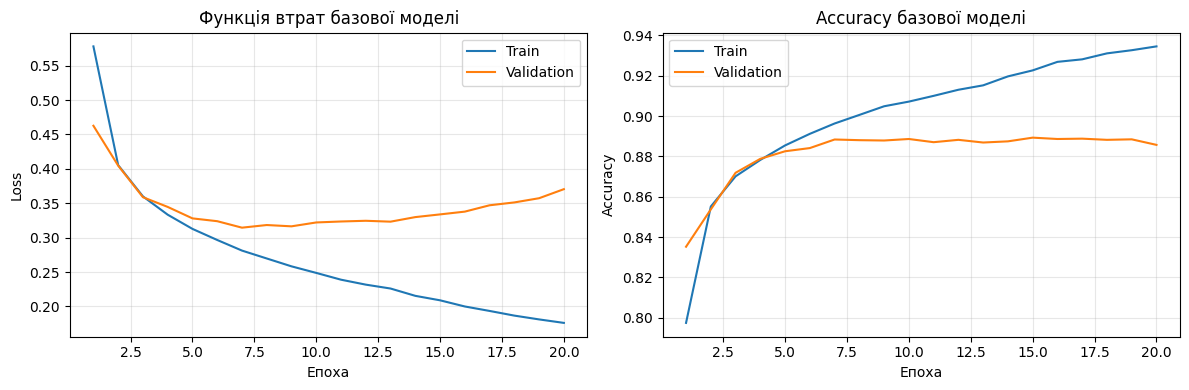

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history_table.index, history_table["loss"], label="Train")
axes[0].plot(history_table.index, history_table["val_loss"], label="Validation")
axes[0].set_title("Функція втрат базової моделі")
axes[0].set_xlabel("Епоха")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(history_table.index, history_table["accuracy"], label="Train")
axes[1].plot(history_table.index, history_table["val_accuracy"], label="Validation")
axes[1].set_title("Accuracy базової моделі")
axes[1].set_xlabel("Епоха")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 10. Аналіз процесу навчання

In [14]:
best_epoch = int(history_table["val_loss"].idxmin())

print("Епоха з найменшим val loss:", best_epoch)
print("Найменший val loss:", round(history_table["val_loss"].min(), 4))
print("Val loss на останній епосі:", round(history_table["val_loss"].iloc[-1], 4))
print("Train loss на останній епосі:", round(history_table["loss"].iloc[-1], 4))
print("Train accuracy на останній епосі:", round(history_table["accuracy"].iloc[-1], 4))
print("Val accuracy на останній епосі:", round(history_table["val_accuracy"].iloc[-1], 4))

Епоха з найменшим val loss: 7
Найменший val loss: 0.3145
Val loss на останній епосі: 0.3705
Train loss на останній епосі: 0.1761
Train accuracy на останній епосі: 0.9346
Val accuracy на останній епосі: 0.8857


Перші 5-7 епох обидві криві loss швидко падають, і train та validation майже збігаються: мережа вчить загальні закономірності. Найменший validation loss (**0.3145**) досягнуто на **7-й епосі**. Далі train loss продовжує падати (до 0.1761 на 20-й епосі), а validation loss починає **зростати** - до 0.3705. Accuracy поводиться так само: на train вона росте до 0.935, а на validation з 7-ї епохи тримається на рівні близько 0.888. Це класична ознака **перенавчання**: після 7-ї епохи мережа запам'ятовує особливості навчальних зображень, а не вчиться розрізняти одяг краще. Недонавчання немає: якість на validation висока (близько 89%).

In [15]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

results = []
histories = {"Базова (128, 64)": base_history.history}
trained_models = {"Базова (128, 64)": base_model}

val_pred = base_model.predict(X_val, verbose=0).argmax(axis=1)
results.append({
    "Конфігурація": "Базова (128, 64)",
    "Параметри": base_model.count_params(),
    "Епохи": len(base_history.history["loss"]),
    "Найкращий val loss": min(base_history.history["val_loss"]),
    "Train accuracy": base_history.history["accuracy"][-1],
    "Accuracy": accuracy_score(y_val, val_pred),
    "Precision": precision_score(y_val, val_pred, average="macro"),
    "Recall": recall_score(y_val, val_pred, average="macro"),
    "F1-score": f1_score(y_val, val_pred, average="macro"),
    "Час, с": base_time
})

print("Метрики базової моделі на валідації збережено")

Метрики базової моделі на валідації збережено


## 11. Вплив архітектури мережі

In [16]:
architectures = {
    "1 шар (128)": ([128], "relu"),
    "Ширша (256, 128)": ([256, 128], "relu"),
    "Глибша (256, 128, 64)": ([256, 128, 64], "relu"),
    "Базова з tanh (128, 64)": ([128, 64], "tanh")
}

for name, (units, activation) in architectures.items():
    tf.keras.utils.set_random_seed(42)

    model = tf.keras.Sequential()
    model.add(tf.keras.layers.Input(shape=(28, 28)))
    model.add(tf.keras.layers.Flatten())
    for n in units:
        model.add(tf.keras.layers.Dense(n, activation=activation))
    model.add(tf.keras.layers.Dense(10, activation="softmax"))

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    start = time.time()
    history = model.fit(X_train, y_train, validation_data=(X_val, y_val),
                        epochs=EPOCHS, batch_size=BATCH_SIZE, verbose=0)
    elapsed = time.time() - start

    val_pred = model.predict(X_val, verbose=0).argmax(axis=1)
    results.append({
        "Конфігурація": name,
        "Параметри": model.count_params(),
        "Епохи": len(history.history["loss"]),
        "Найкращий val loss": min(history.history["val_loss"]),
        "Train accuracy": history.history["accuracy"][-1],
        "Accuracy": accuracy_score(y_val, val_pred),
        "Precision": precision_score(y_val, val_pred, average="macro"),
        "Recall": recall_score(y_val, val_pred, average="macro"),
        "F1-score": f1_score(y_val, val_pred, average="macro"),
        "Час, с": elapsed
    })
    histories[name] = history.history
    trained_models[name] = model
    print(name, "- навчено за", round(elapsed, 1), "с")

architecture_table = pd.DataFrame(results)[["Конфігурація", "Параметри", "Train accuracy", "Accuracy", "Найкращий val loss", "Час, с"]]
architecture_table.rename(columns={"Accuracy": "Val accuracy"}).round(4)

1 шар (128) - навчено за 26.7 с


Ширша (256, 128) - навчено за 34.8 с


Глибша (256, 128, 64) - навчено за 36.6 с


Базова з tanh (128, 64) - навчено за 28.8 с


,Конфігурація,Параметри,Train accuracy,Val accuracy,Найкращий val loss,"Час, с"
0,"Базова (128, 64)",109386,0.9346,0.8858,0.3145,30.4658
1,1 шар (128),101770,0.9281,0.8866,0.3223,26.7159
2,"Ширша (256, 128)",235146,0.9441,0.8935,0.3192,34.8153
3,"Глибша (256, 128, 64)",242762,0.9393,0.8942,0.3240,36.6402
4,"Базова з tanh (128, 64)",109386,0.9373,0.8894,0.3200,28.8325


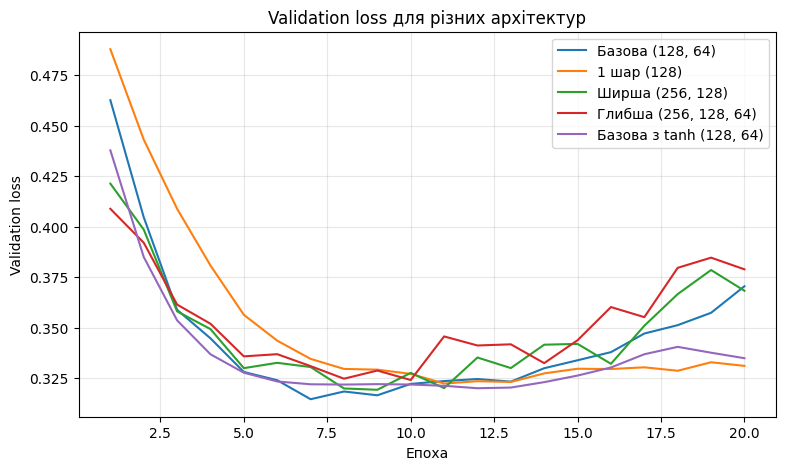

In [17]:
plt.figure(figsize=(9, 5))

for name in ["Базова (128, 64)", "1 шар (128)", "Ширша (256, 128)", "Глибша (256, 128, 64)", "Базова з tanh (128, 64)"]:
    plt.plot(range(1, len(histories[name]["val_loss"]) + 1), histories[name]["val_loss"], label=name)

plt.title("Validation loss для різних архітектур")
plt.xlabel("Епоха")
plt.ylabel("Validation loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

У таблиці для кожної архітектури: кількість параметрів, accuracy на train і validation на останній епосі, найкращий val loss і час навчання.

- **1 шар (128):** найменше параметрів (101 770) і найшвидша (26.7 с), val accuracy 0.887, тобто практично як у базової. Вчиться повільніше (val loss на початку найвищий), але і перенавчається найменше: різниця train - val accuracy 0.042 проти 0.049 у базової.
- **Ширша (256, 128) і глибша (256, 128, 64):** удвічі більше параметрів (235-243 тисячі) і довше навчаються (35-37 с). Val accuracy трохи вища (0.894), але на графіку видно, що вони перенавчаються найсильніше: після 10-ї епохи їхній val loss росте швидше за інших і доходить до 0.37-0.38.
- **tanh замість ReLU:** при тій самій кількості параметрів дає val accuracy 0.889 і плавніший val loss, тобто для цієї задачі обидві функції активації працюють практично однаково.

Висновок: збільшення мережі дає лише невеликий приріст точності (менше 1%), але помітно збільшує кількість параметрів, час навчання і схильність до перенавчання.

## 12. Застосування методів регуляризації

In [18]:
regularizations = {
    "Dropout 0.3": (0.3, 0.0, False),
    "L2 (0.0001)": (0.0, 0.0001, False),
    "Early Stopping": (0.0, 0.0, True),
    "Dropout 0.3 + Early Stopping": (0.3, 0.0, True)
}

for name, (dropout, l2, early) in regularizations.items():
    tf.keras.utils.set_random_seed(42)

    model = tf.keras.Sequential()
    model.add(tf.keras.layers.Input(shape=(28, 28)))
    model.add(tf.keras.layers.Flatten())
    for n in [128, 64]:
        model.add(tf.keras.layers.Dense(n, activation="relu", kernel_regularizer=tf.keras.regularizers.l2(l2)))
        if dropout > 0:
            model.add(tf.keras.layers.Dropout(dropout))
    model.add(tf.keras.layers.Dense(10, activation="softmax"))

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    callbacks = []
    if early:
        callbacks.append(tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True))

    start = time.time()
    history = model.fit(X_train, y_train, validation_data=(X_val, y_val),
                        epochs=EPOCHS, batch_size=BATCH_SIZE, callbacks=callbacks, verbose=0)
    elapsed = time.time() - start

    val_pred = model.predict(X_val, verbose=0).argmax(axis=1)
    results.append({
        "Конфігурація": name,
        "Параметри": model.count_params(),
        "Епохи": len(history.history["loss"]),
        "Найкращий val loss": min(history.history["val_loss"]),
        "Train accuracy": history.history["accuracy"][-1],
        "Accuracy": accuracy_score(y_val, val_pred),
        "Precision": precision_score(y_val, val_pred, average="macro"),
        "Recall": recall_score(y_val, val_pred, average="macro"),
        "F1-score": f1_score(y_val, val_pred, average="macro"),
        "Час, с": elapsed
    })
    histories[name] = history.history
    trained_models[name] = model
    print(name, "- епох:", len(history.history["loss"]), " найкращий val loss:", round(min(history.history["val_loss"]), 4))

Dropout 0.3 - епох: 20  найкращий val loss: 0.3056


L2 (0.0001) - епох: 20  найкращий val loss: 0.3527


Early Stopping - епох: 10  найкращий val loss: 0.3145


Dropout 0.3 + Early Stopping - епох: 20  найкращий val loss: 0.3056


## 13. Порівняння динаміки навчання з базовою моделлю

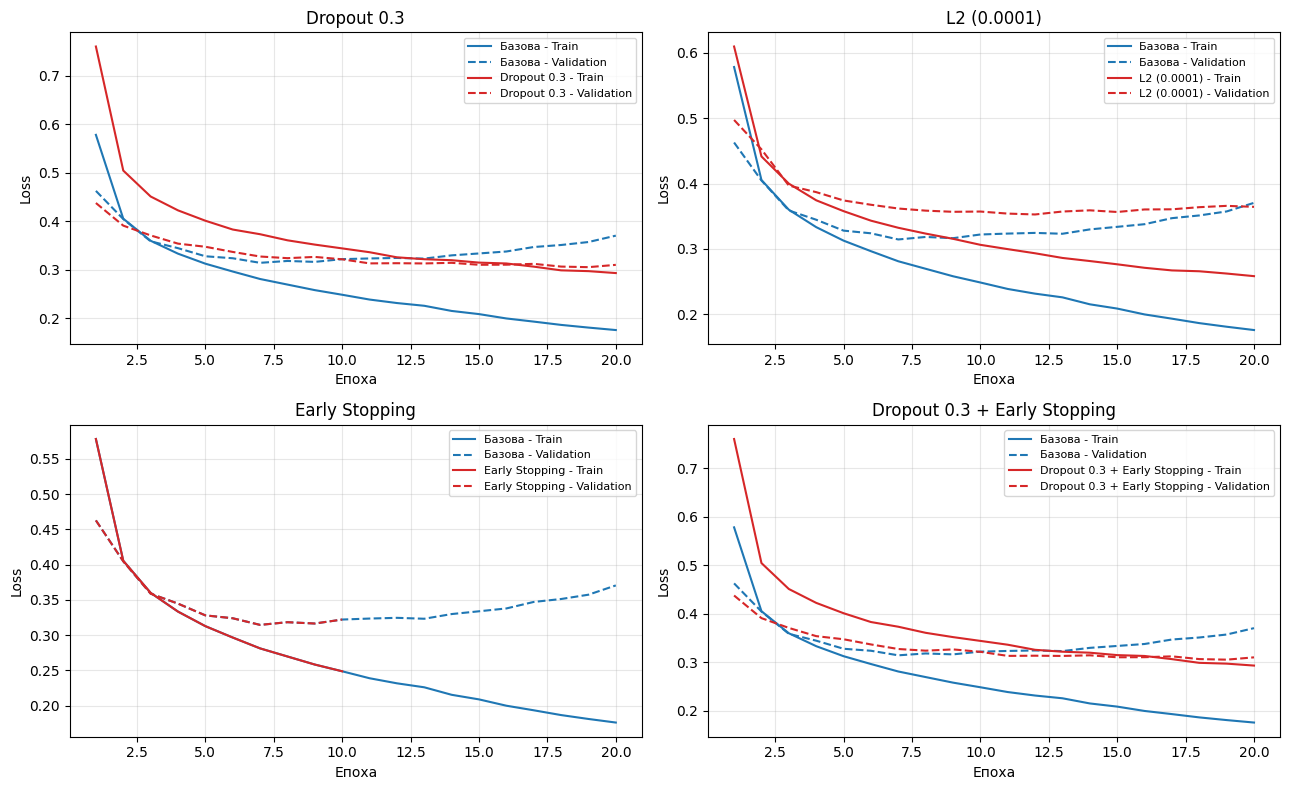

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))

for ax, name in zip(axes.ravel(), regularizations.keys()):
    ax.plot(range(1, EPOCHS + 1), histories["Базова (128, 64)"]["loss"], color="tab:blue", label="Базова - Train")
    ax.plot(range(1, EPOCHS + 1), histories["Базова (128, 64)"]["val_loss"], color="tab:blue", linestyle="--", label="Базова - Validation")
    epochs_done = len(histories[name]["loss"])
    ax.plot(range(1, epochs_done + 1), histories[name]["loss"], color="tab:red", label=name + " - Train")
    ax.plot(range(1, epochs_done + 1), histories[name]["val_loss"], color="tab:red", linestyle="--", label=name + " - Validation")
    ax.set_title(name)
    ax.set_xlabel("Епоха")
    ax.set_ylabel("Loss")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

На графіках синім показано базову модель, червоним - модель з регуляризацією, суцільна лінія - train, пунктир - validation.

- **Dropout 0.3:** під час навчання 30% нейронів випадково вимикаються, тому train loss вищий, ніж у базової. Зате validation loss не росте, а продовжує повільно падати до кінця, і найкращий val loss **0.3056** - найменший серед усіх моделей. Train і validation криві майже злилися, тобто перенавчання прибрано.
- **L2 (0.0001):** штраф за великі ваги стримує train loss, і розрив між train і validation менший, ніж у базової. Val loss тримається рівно близько 0.36. Його значення не можна прямо порівнювати з іншими моделями, бо у функцію втрат L2-моделі входить ще й штраф за ваги, тому вона завжди трохи більша.
- **Early Stopping (patience = 3):** до 7-ї епохи модель повністю повторює базову, бо це та сама мережа. На 10-й епосі навчання зупинилось, бо 3 епохи поспіль val loss не покращувався, і повернулись ваги з 7-ї епохи (val loss 0.3145). Час навчання скоротився майже вдвічі (16.9 с проти 30.5 с).
- **Dropout + Early Stopping:** з Dropout val loss падав до кінця, тому Early Stopping не спрацював і навчання пройшло всі 20 епох. Результат майже такий самий, як у чистого Dropout.

## 14. Метрики всіх конфігурацій на валідаційній вибірці

In [20]:
results_table = pd.DataFrame(results)
results_table[["Конфігурація", "Accuracy", "Precision", "Recall", "F1-score"]].round(4)

,Конфігурація,Accuracy,Precision,Recall,F1-score
0,"Базова (128, 64)",0.8858,0.8893,0.8858,0.8864
1,1 шар (128),0.8866,0.8911,0.8866,0.8875
2,"Ширша (256, 128)",0.8935,0.8945,0.8935,0.8936
3,"Глибша (256, 128, 64)",0.8942,0.8949,0.8942,0.8941
4,"Базова з tanh (128, 64)",0.8894,0.8920,0.8894,0.8896
5,Dropout 0.3,0.8915,0.8927,0.8915,0.8911
6,L2 (0.0001),0.8946,0.8950,0.8946,0.8945
7,Early Stopping,0.8884,0.8895,0.8884,0.8887
8,Dropout 0.3 + Early Stopping,0.8922,0.8927,0.8922,0.8915


Precision, Recall і F1 пораховані як **macro-середнє**: спочатку для кожного з 10 класів окремо, потім просте середнє. Класи збалансовані, тому Accuracy і macro Recall тут збігаються.

Усі конфігурації дуже близькі: accuracy від 0.886 до 0.895, F1 від 0.886 до 0.895. Найкращі за F1 - L2 (**0.8945**), глибша (0.8941) і ширша (0.8936), далі Dropout + Early Stopping (0.8915) і Dropout (0.8911). Найнижчий результат у базової моделі (0.8864), бо вона оцінюється після 20 епох, коли вже перенавчилась.

## 15. Підсумкова таблиця конфігурацій

In [21]:
results_table["Train - Val accuracy"] = results_table["Train accuracy"] - results_table["Accuracy"]

results_table[["Конфігурація", "Параметри", "Епохи", "Найкращий val loss", "Accuracy", "F1-score", "Train - Val accuracy", "Час, с"]].round(4)

,Конфігурація,Параметри,Епохи,Найкращий val loss,Accuracy,F1-score,Train - Val accuracy,"Час, с"
0,"Базова (128, 64)",109386,20,0.3145,0.8858,0.8864,0.0488,30.4658
1,1 шар (128),101770,20,0.3223,0.8866,0.8875,0.0416,26.7159
2,"Ширша (256, 128)",235146,20,0.3192,0.8935,0.8936,0.0506,34.8153
3,"Глибша (256, 128, 64)",242762,20,0.3240,0.8942,0.8941,0.0451,36.6402
4,"Базова з tanh (128, 64)",109386,20,0.3200,0.8894,0.8896,0.0478,28.8325
5,Dropout 0.3,109386,20,0.3056,0.8915,0.8911,-0.0005,30.5132
6,L2 (0.0001),109386,20,0.3527,0.8946,0.8945,0.0288,32.2667
7,Early Stopping,109386,10,0.3145,0.8884,0.8887,0.0188,16.9071
8,Dropout 0.3 + Early Stopping,109386,20,0.3056,0.8922,0.8915,-0.0012,31.0295


Підсумкова таблиця для всіх 9 конфігурацій (з них 3 обов'язкові за завданням: базова, змінена архітектура, регуляризація). Стовпець «Train - Val accuracy» показує, наскільки модель краще працює на навчальних даних, ніж на нових, тобто ступінь перенавчання:
- у базової 0.049, у ширшої 0.051 - найбільше перенавчання;
- у L2 0.029, в Early Stopping 0.019 - помітно менше;
- у Dropout близько 0 (навіть -0.001). Але тут треба врахувати, що train accuracy Dropout-моделі рахується під час навчання, коли частина нейронів вимкнена, тому вона трохи занижена.

Регуляризація не змінює кількість параметрів (109 386, як у базової), а Early Stopping ще й удвічі скорочує час навчання.

## 16. Вибір найбільш придатної конфігурації

In [22]:
best_name = results_table.loc[results_table["F1-score"].idxmax(), "Конфігурація"]

print("Найкраща конфігурація за F1-score на валідації:", best_name)
results_table[results_table["Конфігурація"] == best_name][["Параметри", "Епохи", "Найкращий val loss", "Accuracy", "F1-score", "Train - Val accuracy", "Час, с"]].round(4)

Найкраща конфігурація за F1-score на валідації: L2 (0.0001)


,Параметри,Епохи,Найкращий val loss,Accuracy,F1-score,Train - Val accuracy,"Час, с"
6,109386,20,0.3527,0.8946,0.8945,0.0288,32.2667


За F1-score на валідації найкраща конфігурація - **базова архітектура (128, 64) з L2-регуляризацією** (F1 0.8945, accuracy 0.8946). Глибша мережа майже така сама (0.8941), але має вдвічі більше параметрів (242 762 проти 109 386), довше навчається і сильніше перенавчається (різниця train - val 0.045 проти 0.029). Тобто L2 дає таку саму якість з меншою і стабільнішою моделлю. Dropout мав найкращий val loss (0.3056) і найменше перенавчання, але трохи нижчий F1 (0.8911), тому за обраним критерієм він на другому місці.

## 17. Остаточне оцінювання на тестовій вибірці

In [23]:
final_model = trained_models[best_name]
test_pred = final_model.predict(X_test, verbose=0).argmax(axis=1)

print("Конфігурація:", best_name)
print("Accuracy:", round(accuracy_score(y_test, test_pred), 4))
print("Precision:", round(precision_score(y_test, test_pred, average="macro"), 4))
print("Recall:", round(recall_score(y_test, test_pred, average="macro"), 4))
print("F1-score:", round(f1_score(y_test, test_pred, average="macro"), 4))

Конфігурація: L2 (0.0001)
Accuracy: 0.8833
Precision: 0.8841
Recall: 0.8833
F1-score: 0.8832


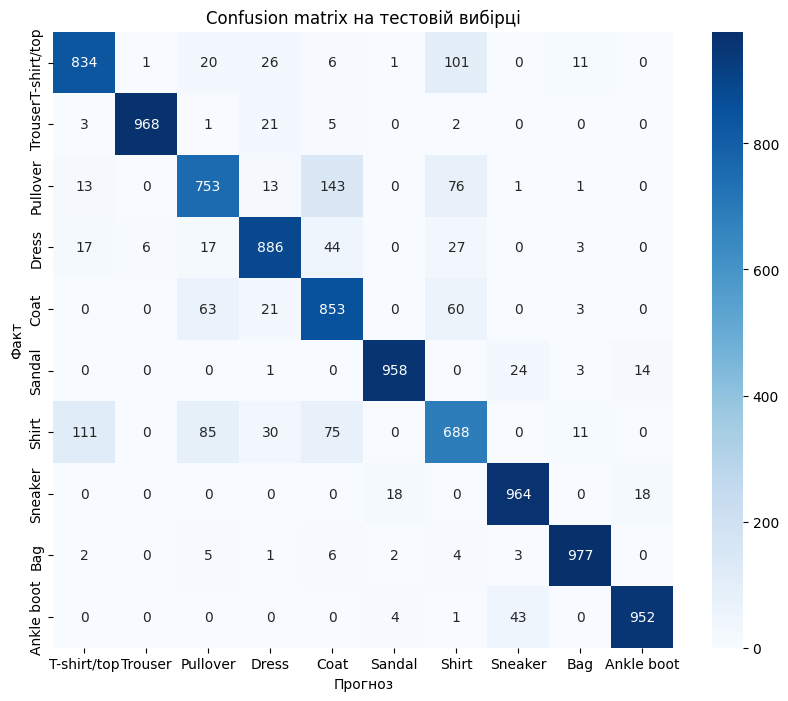

In [24]:
from sklearn.metrics import confusion_matrix

plt.figure(figsize=(10, 8))
sns.heatmap(confusion_matrix(y_test, test_pred), annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.title("Confusion matrix на тестовій вибірці")
plt.xlabel("Прогноз")
plt.ylabel("Факт")
plt.show()

In [25]:
class_results = pd.DataFrame({
    "Клас": class_names,
    "Precision": precision_score(y_test, test_pred, average=None),
    "Recall": recall_score(y_test, test_pred, average=None),
    "F1-score": f1_score(y_test, test_pred, average=None)
})
class_results.sort_values("F1-score").round(3)

,Клас,Precision,Recall,F1-score
6,Shirt,0.717,0.688,0.702
2,Pullover,0.798,0.753,0.775
4,Coat,0.754,0.853,0.800
0,T-shirt/top,0.851,0.834,0.842
3,Dress,0.887,0.886,0.886
7,Sneaker,0.931,0.964,0.947
9,Ankle boot,0.967,0.952,0.960
5,Sandal,0.975,0.958,0.966
8,Bag,0.968,0.977,0.973
1,Trouser,0.993,0.968,0.980


На тестовій вибірці модель з L2 отримала **Accuracy 0.8833, Precision 0.8841, Recall 0.8833, F1-score 0.8832**. Це на 1.1% нижче, ніж на валідації (0.8946), що нормально: валідація використовувалась для вибору моделі, а тест - це повністю нові дані.

Confusion matrix показує, які класи мережа плутає:
- найгірше розпізнається **Shirt** (F1 0.702): сорочки плутаються з футболками (111), пуловерами (85) і пальтами (75);
- далі **Pullover** (0.775) і **Coat** (0.800): 143 пуловери віднесено до пальт;
- **T-shirt/top** часто плутається з Shirt (101).

Тобто помилки виникають між схожими за формою предметами верхнього одягу. Взуття і сумки розпізнаються майже ідеально: Trouser 0.980, Bag 0.973, Sandal 0.966, Ankle boot 0.960. Незначна плутанина є лише між кросівками і черевиками (43).

## 18. Обґрунтування вибору конфігурації

Найбільш придатною для цієї задачі обрано **MLP (128, 64) з L2-регуляризацією (0.0001)**:
- **якість:** найвищий F1 на валідації (0.8945) і F1 0.8832 на тесті;
- **узагальнювальна здатність:** розрив між train і validation удвічі менший, ніж у базової моделі (0.029 проти 0.049), а на тесті результат лише трохи нижчий, ніж на валідації;
- **складність:** 109 386 параметрів, тобто вдвічі менше, ніж у ширшої і глибшої мереж з такою самою якістю;
- **час навчання:** близько 32 с, на рівні базової моделі.

Варто чесно сказати, що різниця між найкращими конфігураціями дуже мала (менше 0.5% F1). Dropout дав майже таку саму якість і найменше перенавчання, тому теж був би хорошим вибором. Для подальшого суттєвого покращення на зображеннях краще підходять згорткові мережі (CNN), бо MLP не враховує розташування пікселів, але завдання їх не вимагало.

## 19. Висновки

- **Процес навчання MLP.** Мережа навчається епохами: дані проходять батчами по 128 зображень, рахується Cross-Entropy, через backpropagation обчислюються градієнти, і Adam оновлює ваги. Перші 5-7 епох train і validation loss падають разом. Базова модель досягла найкращого val loss 0.3145 на 7-й епосі і val accuracy близько 0.89.
- **Вплив архітектури.** Ширша (256, 128) і глибша (256, 128, 64) мережі мають удвічі більше параметрів, довше навчаються і дають лише +0.8% accuracy (0.894 проти 0.886), але перенавчаються сильніше. Один шар (128) майже не поступається базовій моделі і навчається найшвидше. Заміна ReLU на tanh суттєво не змінила результат.
- **Вплив регуляризації.** Dropout 0.3 повністю прибрав перенавчання: val loss падав до кінця, найкращий val loss 0.3056. L2 зменшив розрив між train і validation і дав найвищий F1 (0.8945). Early Stopping зупинив навчання на 10-й епосі, зберіг ваги найкращої 7-ї епохи і вдвічі скоротив час навчання.
- **Перенавчання і недонавчання.** У базовій моделі після 7-ї епохи чітко видно перенавчання: train loss падає до 0.176, а validation loss росте до 0.371, і з'являється розрив train - val accuracy 4.9%. Ширша і глибша мережі перенавчаються ще сильніше. Недонавчання не спостерігалось: усі моделі мають accuracy близько 89%.
- **Найкраща конфігурація.** MLP (128, 64) з L2-регуляризацією: найвищий F1 на валідації, найменший серед повних моделей розрив train - val, удвічі менше параметрів, ніж у великих мереж. На тесті вона показала accuracy 0.883 і F1 0.883. Найчастіше мережа плутає схожий верхній одяг (сорочки, футболки, пуловери, пальта).